# Validación de un modelo de PD: qué monitor delata qué problema

**Perfil:** Riesgo financiero y riesgo de modelos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un modelo en producción se vigila con PSI, Gini y pruebas de calibración. ¿Qué **tipo** de problema detecta cada monitor? ¿Cuántos datos hacen falta para detectar un deterioro real? ¿Por qué ciertas pruebas rechazan casi siempre con muestras grandes?

## Recorrido

1. Modelo campeón (logística) y retador (gradient boosting) entrenados en desarrollo; cuatro escenarios de producción con verdad conocida.
2. **Batería de validación:** Gini con IC (DeLong), KS, calibración (global, pendiente, Hosmer-Lemeshow), PSI del score y CSI por variable.
3. **Matriz escenario × monitor:** qué se dispara en deriva de covariables, deriva de concepto y cambio de tasa base.
4. **Potencia:** tamaño de muestra necesario para detectar el deterioro; el problema de Hosmer-Lemeshow con muestras grandes.
5. **Campeón vs retador:** prueba de DeLong pareada y sobreajuste.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from scipy.stats import rankdata
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

## 2. Datos y escenarios

El mundo verdadero es **logístico** con cinco variables (ingreso, utilización, edad, mora previa, antigüedad). Se simula una población de **desarrollo** y cuatro poblaciones de **producción**, cada una con una **causa distinta** de deterioro:

| escenario | qué cambia | qué NO cambia |
|---|---|---|
| `estable` | nada | todo |
| `deriva_covariables` | la distribución de ingreso y utilización | la relación con el default |
| `deriva_concepto` | el **efecto de la antigüedad** sobre el default (se invierte); el intercepto compensa para conservar la tasa media | las distribuciones de entrada y la tasa de default |
| `cambio_tasa_base` | el nivel general de default (intercepto) | las distribuciones y el ordenamiento |

In [2]:
VARS = ["ingreso", "utilizacion", "edad", "mora_previa", "antiguedad"]
BETA = dict(c=-3.4, ing=-0.00016, util=2.0, edad=-0.010, mora=0.55, antig=-0.07)

def generar(n, esc="estable", seed=0):
    rg = np.random.default_rng(seed)
    mu_ing, d_util = (7.65, 0.10) if esc == "deriva_covariables" else (8.0, 0.0)
    ingreso = rg.lognormal(mu_ing, 0.5, n)
    util = np.clip(rg.beta(2, 3, n) + d_util, 0, 1.2)
    edad = rg.integers(21, 70, n).astype(float)
    mora = rg.poisson(0.4, n).astype(float)
    antig = np.minimum(rg.exponential(4, n), 30)
    b_antig, c = BETA["antig"], BETA["c"]
    if esc == "deriva_concepto": b_antig, c = 0.06, c - 0.50                 # el efecto de la antiguedad se INVIERTE; el intercepto compensa para conservar la PD media
    if esc == "cambio_tasa_base": c += 0.45
    z = c + BETA["ing"] * (ingreso - 3000) + BETA["util"] * util + BETA["edad"] * (edad - 45) + BETA["mora"] * np.minimum(mora, 4) + b_antig * np.minimum(antig, 10)
    p_ver = 1 / (1 + np.exp(-z))
    y = (rg.random(n) < p_ver).astype(int)
    return pd.DataFrame({"ingreso": ingreso, "utilizacion": util, "edad": edad, "mora_previa": mora, "antiguedad": antig}), y, p_ver

X_dev, y_dev, p_dev_ver = generar(30_000, "estable", seed=1)
print(f"Desarrollo: n={len(y_dev)}, tasa de default = {y_dev.mean():.3%}, malos = {y_dev.sum()}")
ESCENARIOS = ["estable", "deriva_covariables", "deriva_concepto", "cambio_tasa_base"]
N_PROD = 40_000
PROD = {e: generar(N_PROD, e, seed=100 + i) for i, e in enumerate(ESCENARIOS)}
print(f"Muestras de produccion de {N_PROD:,} creditos cada una.")
pd.DataFrame({e: {"tasa_default_real": PROD[e][1].mean(), "PD_verdadera_media": PROD[e][2].mean()} for e in ESCENARIOS}).T.round(4)

Desarrollo: n=30000, tasa de default = 7.330%, malos = 2199
Muestras de produccion de 40,000 creditos cada una.


,tasa_default_real,PD_verdadera_media
estable,0.0725,0.0744
deriva_covariables,0.1013,0.1007
deriva_concepto,0.0726,0.0726
cambio_tasa_base,0.1098,0.1108


## 3. Campeón y retador

- **Campeón:** regresión logística sobre las variables estandarizadas.
- **Retador:** gradient boosting (`HistGradientBoostingClassifier`).
Ambos se entrenan **solo con desarrollo**.

In [3]:
esc_std = StandardScaler().fit(X_dev)
campeon = LogisticRegression(max_iter=2000).fit(esc_std.transform(X_dev), y_dev)
retador = HistGradientBoostingClassifier(random_state=0).fit(X_dev, y_dev)
pred_c = lambda X: campeon.predict_proba(esc_std.transform(X))[:, 1]
pred_r = lambda X: retador.predict_proba(X)[:, 1]
auc = lambda y, p: roc_auc_score(y, p)
print(f"Gini en desarrollo (entrenamiento): campeon {2 * auc(y_dev, pred_c(X_dev)) - 1:.3f} | retador {2 * auc(y_dev, pred_r(X_dev)) - 1:.3f}")
print(f"Gini en desarrollo con la PD VERDADERA (techo): {2 * auc(y_dev, p_dev_ver) - 1:.3f}")

Gini en desarrollo (entrenamiento): campeon 0.342 | retador 0.541
Gini en desarrollo con la PD VERDADERA (techo): 0.343


## 4. La batería de validación

### 4.1 Gini con intervalo de confianza (DeLong)

El AUC de Mann-Whitney se puede escribir como el promedio de **valores de ubicación** (*placement values*) de positivos y negativos. La varianza de DeLong sale de la varianza de esos valores. Se implementa con rangos, $O(n\log n)$, y se **verifica contra un bootstrap**.

In [4]:
def placement(y, s):
    pos, neg = s[y == 1], s[y == 0]; m, n = len(pos), len(neg)
    r_all = rankdata(np.r_[pos, neg]); v10 = (r_all[:m] - rankdata(pos)) / n; v01 = 1 - (r_all[m:] - rankdata(neg)) / m
    return v10, v01

def auc_delong(y, s):
    v10, v01 = placement(np.asarray(y), np.asarray(s)); m, n = len(v10), len(v01)
    return float(v10.mean()), float(v10.var(ddof=1) / m + v01.var(ddof=1) / n)

def gini_ic(y, s, nivel=0.95):
    a, v = auc_delong(y, s); z = stats.norm.ppf(0.5 + nivel / 2); se = np.sqrt(v)
    return {"gini": 2 * a - 1, "se": 2 * se, "lo": 2 * (a - z * se) - 1, "hi": 2 * (a + z * se) - 1}

def delong_pareado(y, s1, s2):
    y = np.asarray(y); a1, a2 = [], []; V10, V01 = [], []
    for s in (s1, s2):
        v10, v01 = placement(y, np.asarray(s)); V10.append(v10); V01.append(v01)
    m, n = len(V10[0]), len(V01[0])
    S10 = np.cov(np.vstack(V10)); S01 = np.cov(np.vstack(V01))
    var = (S10[0, 0] + S10[1, 1] - 2 * S10[0, 1]) / m + (S01[0, 0] + S01[1, 1] - 2 * S01[0, 1]) / n
    d = V10[0].mean() - V10[1].mean()
    z = d / np.sqrt(var); return d, z, 2 * (1 - stats.norm.cdf(abs(z)))

# verificacion contra bootstrap en una muestra de produccion
Xp, yp, _ = PROD["estable"]; sp = pred_c(Xp)
a_dl, v_dl = auc_delong(yp, sp)
rg = np.random.default_rng(0)
bs = [roc_auc_score(yp[i], sp[i]) for i in (rg.integers(0, len(yp), len(yp)) for _ in range(300))]
print(f"AUC = {a_dl:.4f} (sklearn {roc_auc_score(yp, sp):.4f}) | SE DeLong = {np.sqrt(v_dl):.5f} | SE bootstrap = {np.std(bs):.5f}")

AUC = 0.6800 (sklearn 0.6800) | SE DeLong = 0.00519 | SE bootstrap = 0.00519


### 4.2 Calibración: tres lentes

1. **Global (calibration-in-the-large):** ¿la PD media coincide con la tasa observada? $z=(O-E)/\sqrt{\sum p_i(1-p_i)}$.
2. **Intercepto y pendiente de calibración:** se ajusta $\operatorname{logit}P(y=1)=a+b\,\operatorname{logit}(\hat p)$. Calibrado: $a=0,\ b=1$. Una pendiente menor que 1 indica predicciones demasiado extremas (sobreajuste).
3. **Hosmer-Lemeshow:** $\chi^2$ por grupos de PD. (Se examina su comportamiento con $n$ en la sección 7.)

In [5]:
def logit(p): p = np.clip(p, 1e-9, 1 - 1e-9); return np.log(p / (1 - p))

def calibracion(y, p, grupos=10):
    y = np.asarray(y); p = np.asarray(p)
    E, O = p.sum(), y.sum(); z = (O - E) / np.sqrt((p * (1 - p)).sum())
    m = sm.GLM(y, sm.add_constant(logit(p)), family=sm.families.Binomial()).fit()
    g = pd.qcut(p, grupos, labels=False, duplicates="drop"); df = pd.DataFrame({"y": y, "p": p, "g": g}).groupby("g").agg(O=("y", "sum"), E=("p", "sum"), n=("y", "size"))
    hl = float(((df["O"] - df["E"]) ** 2 / (df["E"] * (1 - df["E"] / df["n"]))).sum()); gl = len(df) - 2
    z_b = (m.params[1] - 1) / m.bse[1]
    return {"obs/pred": O / E, "z_global": z, "p_global": 2 * (1 - stats.norm.cdf(abs(z))), "intercepto": m.params[0], "pendiente": m.params[1], "p_pendiente": 2 * (1 - stats.norm.cdf(abs(z_b))),
            "HL_chi2": hl, "HL_p": 1 - stats.chi2.cdf(hl, gl)}

def hl_p(y, p, grupos=10):
    g = pd.qcut(p, grupos, labels=False, duplicates="drop"); df = pd.DataFrame({"y": y, "p": p, "g": g}).groupby("g").agg(O=("y", "sum"), E=("p", "sum"), n=("y", "size"))
    hl = float(((df["O"] - df["E"]) ** 2 / (df["E"] * (1 - df["E"] / df["n"]))).sum()); return 1 - stats.chi2.cdf(hl, len(df) - 2)

def ks(y, p):
    o = np.argsort(p); yy = np.asarray(y)[o]
    return float(np.max(np.abs(np.cumsum(yy) / yy.sum() - np.cumsum(1 - yy) / (1 - yy).sum())))

def psi(esperado, actual, bins=10):
    e, a = np.asarray(esperado, float), np.asarray(actual, float)
    cortes = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1))); cortes[0], cortes[-1] = -np.inf, np.inf
    pe = np.clip(np.histogram(e, cortes)[0] / len(e), 1e-4, None); pa = np.clip(np.histogram(a, cortes)[0] / len(a), 1e-4, None)
    return float(((pa - pe) * np.log(pa / pe)).sum())

# caso de verificacion: modelo perfectamente calibrado => intercepto ~0, pendiente ~1, obs/pred ~1
rg = np.random.default_rng(1); p_cal = rg.beta(1, 14, 60_000); y_cal = (rg.random(60_000) < p_cal).astype(int)
cal_ok = calibracion(y_cal, p_cal)
print("Verificacion con un modelo calibrado por construccion:", {k: round(v, 3) for k, v in cal_ok.items()})

Verificacion con un modelo calibrado por construccion: {'obs/pred': np.float64(1.011), 'z_global': np.float64(0.77), 'p_global': np.float64(0.441), 'intercepto': np.float64(0.037), 'pendiente': np.float64(1.011), 'p_pendiente': np.float64(0.592), 'HL_chi2': 6.391, 'HL_p': np.float64(0.604)}


## 5. Resultado en desarrollo (referencia) y por escenario

Se calcula toda la batería para el **campeón** sobre cada escenario de producción. La referencia de desarrollo es la muestra de entrenamiento (nótese que sobreestima el desempeño real fuera de muestra).

In [6]:
sdev = pred_c(X_dev)
G_TRAIN = gini_ic(y_dev, sdev)["gini"]
# REFERENCIA DE VALIDACION: una muestra grande de la misma poblacion de desarrollo, NO usada para entrenar.
# (Una primera version comparaba contra el Gini de entrenamiento, un solo punto ruidoso: el Gini tiene una desviacion
#  de ~0.02 con 12.000 creditos y 7% de default; una referencia puntual y pequena hace inutil la comparacion.)
X_val, y_val, _ = generar(60_000, "estable", seed=7); s_val = pred_c(X_val)
GI_REF = gini_ic(y_val, s_val); G_REF, SE_REF = GI_REF["gini"], GI_REF["se"]
print(f"Gini campeon: entrenamiento = {G_TRAIN:.3f} | validacion (n=60.000) = {G_REF:.3f} +- {1.96 * SE_REF:.3f} (IC95%)")

def test_caida_gini(y, s):
    gi = gini_ic(y, s); z = (gi["gini"] - G_REF) / np.sqrt(gi["se"] ** 2 + SE_REF ** 2)
    return gi, z, stats.norm.cdf(z)                                   # p unilateral: H1 = el Gini cayo

def bateria(esc):
    X, y, _ = PROD[esc]; s = pred_c(X); gi, z, p_gini = test_caida_gini(y, s); cal = calibracion(y, s)
    csi = {v: psi(X_val[v], X[v]) for v in VARS}
    return {"Gini": gi["gini"], "Gini_se": gi["se"], "dGini_vs_ref": gi["gini"] - G_REF, "z_caida": z, "p_caida": p_gini, "KS": ks(y, s), "obs/pred": cal["obs/pred"], "p_global": cal["p_global"],
            "pendiente": cal["pendiente"], "p_pendiente": cal["p_pendiente"], "intercepto": cal["intercepto"], "HL_p": cal["HL_p"], "PSI_score": psi(s_val, s), "CSI_max": max(csi.values()), "CSI_var": max(csi, key=csi.get)}

bat = pd.DataFrame({e: bateria(e) for e in ESCENARIOS}).T
cols_num = [c for c in bat.columns if c != "CSI_var"]
bat[cols_num] = bat[cols_num].astype(float)
bat.round(4)

Gini campeon: entrenamiento = 0.342 | validacion (n=60.000) = 0.361 +- 0.016 (IC95%)


,Gini,Gini_se,dGini_vs_ref,z_caida,p_caida,KS,obs/pred,p_global,pendiente,p_pendiente,intercepto,HL_p,PSI_score,CSI_max,CSI_var
estable,0.3600,0.0104,-0.0007,-0.0526,0.4790,0.2698,0.9928,0.6804,1.0454,0.1422,0.0996,0.2288,0.0001,0.0006,ingreso
deriva_covariables,0.3411,0.0089,-0.0195,-1.6007,0.0547,0.2568,1.0184,0.2114,1.0290,0.2985,0.0810,0.5593,0.3430,0.4621,ingreso
deriva_concepto,0.2928,0.0107,-0.0678,-5.0046,0.0000,0.2111,0.9943,0.7470,0.8592,0.0000,-0.3441,0.0001,0.0001,0.0004,utilizacion
cambio_tasa_base,0.3532,0.0085,-0.0075,-0.6305,0.2642,0.2578,1.4951,0.0000,1.0238,0.3645,0.5168,0.0000,0.0003,0.0005,antiguedad


## 6. La matriz escenario × monitor

Se definen reglas de **alerta** que combinan **significancia estadística y materialidad** (un cambio puede ser significativo pero irrelevante, o relevante pero no significativo con muestra pequeña):

| monitor | alerta si |
|---|---|
| PSI del score | > 0,25 |
| CSI máximo | > 0,25 |
| caída de Gini | la prueba unilateral de caída (contra el Gini de validación, con su incertidumbre) da $p<0{,}05$ **y** la caída es mayor que 0,03 |
| calibración global | $|\text{obs/pred}-1|>15\%$ **y** $p<0{,}01$ |
| pendiente de calibración | $|b-1|>0{,}15$ **y** $p<0{,}01$ |

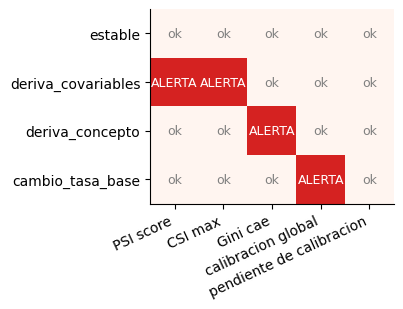

,PSI score,CSI max,Gini cae,calibracion global,pendiente de calibracion
estable,False,False,False,False,False
deriva_covariables,True,True,False,False,False
deriva_concepto,False,False,True,False,False
cambio_tasa_base,False,False,False,True,False


In [7]:
alertas = pd.DataFrame({
    "PSI score": bat["PSI_score"] > 0.25,
    "CSI max": bat["CSI_max"] > 0.25,
    "Gini cae": (bat["p_caida"] < 0.05) & (bat["dGini_vs_ref"] < -0.03),
    "calibracion global": ((bat["obs/pred"] - 1).abs() > 0.15) & (bat["p_global"] < 0.01),
    "pendiente de calibracion": ((bat["pendiente"] - 1).abs() > 0.15) & (bat["p_pendiente"] < 0.01),
})
fig, ax = plt.subplots(figsize=(8.5, 3.2)); ax.imshow(alertas.astype(int).values, cmap="Reds", vmin=0, vmax=1.4); ax.grid(False)
ax.set_xticks(range(alertas.shape[1])); ax.set_xticklabels(alertas.columns, rotation=25, ha="right"); ax.set_yticks(range(len(alertas))); ax.set_yticklabels(alertas.index)
for i in range(alertas.shape[0]):
    for j in range(alertas.shape[1]): ax.text(j, i, "ALERTA" if alertas.iloc[i, j] else "ok", ha="center", va="center", fontsize=9, color="white" if alertas.iloc[i, j] else "gray")
plt.tight_layout(); plt.show()
alertas

In [8]:
print("Lectura:")
for e in ESCENARIOS:
    disp = [c for c in alertas.columns if alertas.loc[e, c]]
    print(f"  {e:20s}: " + (", ".join(disp) if disp else "ningun monitor se dispara"))
print()
dc = bat.loc["deriva_covariables"]; dk = bat.loc["deriva_concepto"]; tb = bat.loc["cambio_tasa_base"]
print(f"  Deriva de covariables: PSI score = {dc['PSI_score']:.2f}, CSI max = {dc['CSI_max']:.2f} en '{dc['CSI_var']}'; el Gini cambia {dc['dGini_vs_ref']:+.3f} (p de caida = {dc['p_caida']:.3f}) y la calibracion queda en obs/pred = {dc['obs/pred']:.2f}.")
print(f"  Deriva de concepto: PSI score = {dk['PSI_score']:.3f} y CSI max = {dk['CSI_max']:.3f} (silenciosos); el Gini cae {dk['dGini_vs_ref']:+.3f} (p = {dk['p_caida']:.1e}) y obs/pred = {dk['obs/pred']:.2f}.")
print(f"  Cambio de tasa base: ordena igual (dGini = {tb['dGini_vs_ref']:+.3f}) pero obs/pred = {tb['obs/pred']:.2f} (p = {tb['p_global']:.1e}).")

Lectura:
  estable             : ningun monitor se dispara
  deriva_covariables  : PSI score, CSI max
  deriva_concepto     : Gini cae
  cambio_tasa_base    : calibracion global

  Deriva de covariables: PSI score = 0.34, CSI max = 0.46 en 'ingreso'; el Gini cambia -0.020 (p de caida = 0.055) y la calibracion queda en obs/pred = 1.02.
  Deriva de concepto: PSI score = 0.000 y CSI max = 0.000 (silenciosos); el Gini cae -0.068 (p = 2.8e-07) y obs/pred = 0.99.
  Cambio de tasa base: ordena igual (dGini = -0.008) pero obs/pred = 1.50 (p = 0.0e+00).


**Qué se aprende.** Cada monitor responde a **un tipo** de problema: el PSI mide cambios en **las entradas**; el Gini, en **el ordenamiento**; la calibración, en **el nivel**. Ninguno sustituye a los otros. En particular, **PSI silencioso no significa modelo sano** (deriva de concepto) y **PSI en rojo no significa modelo roto** (deriva de covariables).

## 7. Potencia y tamaño de muestra

### 7.1 ¿Cuántos datos hacen falta para detectar la deriva de concepto?

Se repite el monitoreo de Gini con muestras de producción de tamaño $n$ y se mide, sobre 200 réplicas, la frecuencia con que el **límite superior del IC95 %** cae por debajo del Gini de desarrollo, **bajo `deriva_concepto`** (potencia) y **bajo `estable`** (falsas alarmas).

In [9]:
def potencia_gini(esc, n, R=150, seed0=0):
    rech = 0
    for i in range(R):
        X, y, _ = generar(n, esc, seed=seed0 + i)
        gi, z, p = test_caida_gini(y, pred_c(X))
        rech += (p < 0.05) and (gi["gini"] - G_REF < -0.03)
    return rech / R

filas = []
for n in (2000, 5000, 10_000, 25_000, 50_000):
    filas.append({"n": n, "potencia (deriva de concepto)": potencia_gini("deriva_concepto", n, seed0=10_000 + n), "falsas alarmas (estable)": potencia_gini("estable", n, seed0=50_000 + n)})
pot = pd.DataFrame(filas).set_index("n")
pot.round(3)

,potencia (deriva de concepto),falsas alarmas (estable)
n,,
2000,0.4400,0.0530
5000,0.7000,0.0730
10000,0.9070,0.0800
25000,1.0000,0.0470
50000,1.0000,0.0070


In [10]:
print("Lectura:")
n80 = next((n for n in pot.index if pot.loc[n, "potencia (deriva de concepto)"] >= 0.8), None)
caida_real = bat.loc["deriva_concepto", "dGini_vs_ref"]
sd_gini = np.std([2 * roc_auc_score(*generar(12_000, "estable", seed=s_)[1:2], pred_c(generar(12_000, "estable", seed=s_)[0])) - 1 for s_ in range(30)])
print(f"  La caida de Gini medida bajo la deriva de concepto (n={N_PROD:,}) es {caida_real:+.3f}.")
print(f"  Menor n probado con 80% de potencia para detectarla: {n80}.")
print(f"  Con n=2000 la potencia es {pot.loc[2000, 'potencia (deriva de concepto)']:.0%} y con n=10000, {pot.loc[10000, 'potencia (deriva de concepto)']:.0%}: con ~7% de default, una validacion con pocos miles de creditos APRUEBA un modelo que SI se deterioro.")
print(f"  Falsas alarmas bajo el escenario estable: " + ", ".join(f"{n}: {v:.0%}" for n, v in pot["falsas alarmas (estable)"].items()) + " (regla: p<0.05 unilateral y caida > 0.03).")
print(f"  Desviacion estandar del Gini del campeon en 30 muestras de 12.000 creditos (poblacion estable): {sd_gini:.4f}: el ruido de muestreo es del mismo orden que los deterioros que se quieren detectar.")

Lectura:


  La caida de Gini medida bajo la deriva de concepto (n=40,000) es -0.068.
  Menor n probado con 80% de potencia para detectarla: 10000.
  Con n=2000 la potencia es 44% y con n=10000, 91%: con ~7% de default, una validacion con pocos miles de creditos APRUEBA un modelo que SI se deterioro.
  Falsas alarmas bajo el escenario estable: 2000: 5%, 5000: 7%, 10000: 8%, 25000: 5%, 50000: 1% (regla: p<0.05 unilateral y caida > 0.03).
  Desviacion estandar del Gini del campeon en 30 muestras de 12.000 creditos (poblacion estable): 0.0220: el ruido de muestreo es del mismo orden que los deterioros que se quieren detectar.


### 7.2 Hosmer-Lemeshow: el problema de las muestras grandes

HL contrasta "calibración perfecta" contra "algún desvío". Con una muestra enorme, **cualquier** desvío, por pequeño que sea y por irrelevante que sea en la práctica, se vuelve estadísticamente significativo. Se verifica con un modelo calibrado al **95 %** (PD predicha 5 % por encima de la verdadera, un error pequeño y quizá aceptable).

In [11]:
filas = []
for n in (2_000, 10_000, 50_000, 200_000):
    rg = np.random.default_rng(n); R = 300 if n <= 50_000 else 100
    rechaza_5 = rechaza_0 = 0
    for i in range(R):
        p_ver_ = rg.beta(1, 14, n); y_ = (rg.random(n) < p_ver_).astype(int)
        rechaza_5 += hl_p(y_, p_ver_ * 1.05) < 0.05            # 5% de sobreestimacion
        rechaza_0 += hl_p(y_, p_ver_) < 0.05                   # calibrado exacto
    filas.append({"n": n, "rechaza_si_calibrado_exacto": rechaza_0 / R, "rechaza_si_PD_5%_mayor": rechaza_5 / R, "replicas": R})
hl = pd.DataFrame(filas).set_index("n")
hl.round(3)

,rechaza_si_calibrado_exacto,rechaza_si_PD_5%_mayor,replicas
n,,,
2000,0.1100,0.1130,300
10000,0.0870,0.1730,300
50000,0.1330,0.6170,300
200000,0.1300,1.0000,100


In [12]:
print("Lectura:")
print(f"  Con un modelo EXACTAMENTE calibrado, HL rechaza " + ", ".join(f"{v:.1%} (n={n:,})" for n, v in hl["rechaza_si_calibrado_exacto"].items()) + " (nominal 5%).")
print("  Con PD muy bajas y agrupadas en deciles, los conteos esperados por grupo son pequenos y la aproximacion chi-cuadrado no es exacta: el nivel real de HL no es exactamente 5%.")
print(f"  Con un error pequeno y estable (+5% en la PD), la tasa de rechazo sube de {hl['rechaza_si_PD_5%_mayor'].iloc[0]:.0%} con n={hl.index[0]:,} a {hl['rechaza_si_PD_5%_mayor'].iloc[-1]:.0%} con n={hl.index[-1]:,}.")
print("  Rechazar con una muestra enorme dice que HAY un desvio, no que sea IMPORTANTE: hay que mirar la MAGNITUD (obs/pred, pendiente) ademas del p-valor.")

Lectura:
  Con un modelo EXACTAMENTE calibrado, HL rechaza 11.0% (n=2,000), 8.7% (n=10,000), 13.3% (n=50,000), 13.0% (n=200,000) (nominal 5%).
  Con PD muy bajas y agrupadas en deciles, los conteos esperados por grupo son pequenos y la aproximacion chi-cuadrado no es exacta: el nivel real de HL no es exactamente 5%.
  Con un error pequeno y estable (+5% en la PD), la tasa de rechazo sube de 11% con n=2,000 a 100% con n=200,000.
  Rechazar con una muestra enorme dice que HAY un desvio, no que sea IMPORTANTE: hay que mirar la MAGNITUD (obs/pred, pendiente) ademas del p-valor.


## 8. Campeón frente a retador

### 8.1 Prueba de DeLong pareada

Con el mismo conjunto de producción, se contrasta si el AUC del retador difiere del del campeón, teniendo en cuenta que ambos modelos se evalúan sobre las **mismas** observaciones (correlacionados).

In [13]:
filas = []
for e in ESCENARIOS:
    X, y, pv = PROD[e]; sc, sr = pred_c(X), pred_r(X)
    d, z, p = delong_pareado(y, sr, sc)
    filas.append({"escenario": e, "Gini campeon": 2 * auc(y, sc) - 1, "Gini retador": 2 * auc(y, sr) - 1, "dAUC (retador-campeon)": d, "z": z, "p_DeLong": p, "Gini PD verdadera (techo)": 2 * auc(y, pv) - 1})
cr = pd.DataFrame(filas).set_index("escenario")
cr.round(4)

,Gini campeon,Gini retador,dAUC (retador-campeon),z,p_DeLong,Gini PD verdadera (techo)
escenario,,,,,,
estable,0.3600,0.3275,-0.0162,-6.8446,0.0000,0.3619
deriva_covariables,0.3411,0.3131,-0.0140,-6.6302,0.0000,0.3447
deriva_concepto,0.2928,0.2665,-0.0132,-5.2748,0.0000,0.3396
cambio_tasa_base,0.3532,0.3221,-0.0155,-7.7938,0.0000,0.3571


In [14]:
g_tr_c, g_tr_r = 2 * auc(y_dev, pred_c(X_dev)) - 1, 2 * auc(y_dev, pred_r(X_dev)) - 1
print("Lectura:")
print(f"  En ENTRENAMIENTO el retador parece mejor ({g_tr_r:.3f} vs {g_tr_c:.3f}), pero eso mide memorizacion: es la brecha de sobreajuste.")
for e in ESCENARIOS:
    f = cr.loc[e]
    print(f"  {e:20s}: dAUC = {f['dAUC (retador-campeon)']:+.4f} (p = {f['p_DeLong']:.3f}) -> {'diferencia significativa' if f['p_DeLong'] < 0.05 else 'sin diferencia significativa'}; el techo es {f['Gini PD verdadera (techo)']:.3f}.")
peor_en = int((cr["dAUC (retador-campeon)"] < 0).sum())
print(f"  El retador es PEOR que el campeon fuera de muestra en {peor_en} de {len(cr)} escenarios: en entrenamiento memoriza (Gini {g_tr_r:.2f}) y fuera de muestra generaliza peor que un modelo logistico que coincide con el mundo verdadero.")
print("  El mundo verdadero ES logistico; un retador mas flexible no tiene nada que ganar y su flexibilidad extra solo anade ruido. Con una relacion no lineal la conclusion podria ser la contraria.")

Lectura:
  En ENTRENAMIENTO el retador parece mejor (0.541 vs 0.342), pero eso mide memorizacion: es la brecha de sobreajuste.
  estable             : dAUC = -0.0162 (p = 0.000) -> diferencia significativa; el techo es 0.362.
  deriva_covariables  : dAUC = -0.0140 (p = 0.000) -> diferencia significativa; el techo es 0.345.
  deriva_concepto     : dAUC = -0.0132 (p = 0.000) -> diferencia significativa; el techo es 0.340.
  cambio_tasa_base    : dAUC = -0.0155 (p = 0.000) -> diferencia significativa; el techo es 0.357.
  El retador es PEOR que el campeon fuera de muestra en 4 de 4 escenarios: en entrenamiento memoriza (Gini 0.54) y fuera de muestra generaliza peor que un modelo logistico que coincide con el mundo verdadero.
  El mundo verdadero ES logistico; un retador mas flexible no tiene nada que ganar y su flexibilidad extra solo anade ruido. Con una relacion no lineal la conclusion podria ser la contraria.


## 9. Pruebas automáticas

In [15]:
# 9.1 DeLong coincide con sklearn y con el bootstrap
assert abs(a_dl - roc_auc_score(yp, sp)) < 1e-9
assert abs(np.sqrt(v_dl) / np.std(bs) - 1) < 0.2
# 9.2 DeLong pareado: un modelo contra si mismo da diferencia 0 y z indefinido pero finito con ruido; contra uno peor da z significativo
d0, z0, p0 = delong_pareado(yp, sp, sp + 1e-12 * np.random.default_rng(0).standard_normal(len(sp)))
assert abs(d0) < 1e-6
peor = sp + np.random.default_rng(1).normal(0, np.std(sp) * 2, len(sp))
assert delong_pareado(yp, sp, peor)[2] < 0.01
# 9.3 la calibracion de un modelo calibrado por construccion da intercepto~0, pendiente~1, obs/pred~1
assert abs(cal_ok["obs/pred"] - 1) < 0.03 and abs(cal_ok["pendiente"] - 1) < 0.05 and abs(cal_ok["intercepto"]) < 0.15
# 9.4 el PSI de una distribucion contra si misma es ~0 y crece con el desplazamiento
x_ = np.random.default_rng(2).normal(size=50_000)
assert psi(x_, x_) < 1e-6 and psi(x_, x_ + 0.5) > psi(x_, x_ + 0.1) > 0
# 9.5 matriz escenario x monitor: cada monitor se dispara en el escenario que corresponde
assert alertas.loc["estable"].sum() == 0, "en el escenario estable no deberia haber alertas"
assert alertas.loc["deriva_covariables", ["PSI score", "CSI max"]].all()
assert not alertas.loc["deriva_concepto", ["PSI score", "CSI max"]].any(), "el PSI no debe ver la deriva de concepto"
assert alertas.loc["deriva_concepto", "Gini cae"] and bat.loc["deriva_concepto", "dGini_vs_ref"] < -0.05
assert alertas.loc["cambio_tasa_base", "calibracion global"] and not alertas.loc["cambio_tasa_base", "Gini cae"]
assert abs(bat.loc["cambio_tasa_base", "dGini_vs_ref"]) < 0.03
# 9.6 la deriva de covariables NO degrada el ordenamiento de forma material, aunque el PSI la marque
assert not alertas.loc["deriva_covariables", "Gini cae"] and abs(bat.loc["deriva_covariables", "dGini_vs_ref"]) < abs(bat.loc["deriva_concepto", "dGini_vs_ref"])
# 9.7 la potencia crece con n y es baja con pocos casos; sin deterioro, las falsas alarmas son bajas
assert pot["potencia (deriva de concepto)"].is_monotonic_increasing and pot.loc[2000, "potencia (deriva de concepto)"] < 0.5 and pot.loc[50_000, "potencia (deriva de concepto)"] > 0.8
assert pot["falsas alarmas (estable)"].max() < 0.1
# 9.8 HL rechaza cada vez mas con n ante un desvio pequeno
assert hl["rechaza_si_PD_5%_mayor"].iloc[-1] > hl["rechaza_si_PD_5%_mayor"].iloc[0] + 0.3 and hl["rechaza_si_PD_5%_mayor"].iloc[-1] > 0.9
assert hl["rechaza_si_calibrado_exacto"].max() < 0.3
# 9.9 el retador parece mejor en entrenamiento (sobreajuste) y es peor fuera de muestra en todos los escenarios
assert g_tr_r > g_tr_c + 0.1
assert (cr["dAUC (retador-campeon)"] < 0).all() and cr.loc["estable", "p_DeLong"] < 0.01
assert (cr["Gini campeon"] <= cr["Gini PD verdadera (techo)"] + 0.03).all()
# 9.10 la referencia de validacion es precisa
assert SE_REF < 0.015
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Cada monitor mira una cosa | PSI/CSI: entradas; Gini: ordenamiento; calibración: nivel | Usar los tres; ninguno sustituye a los otros |
| Deriva de covariables | PSI/CSI en alerta sin deterioro apreciable del Gini | Una alarma de PSI no implica modelo roto: confirmar con desempeño |
| Deriva de concepto | PSI y CSI silenciosos; el Gini cae | PSI silencioso no implica modelo sano |
| Cambio de tasa base | El orden se mantiene; solo la calibración lo ve | Monitorear obs/pred y recalibrar |
| Potencia | Con ~7 % de default, una caída real de Gini de ≈0,07 no se detecta de forma fiable con pocos miles de créditos; el ruido de muestreo del Gini es de ≈0,02 con 12.000 | Fijar el tamaño de muestra mínimo de la validación y compararlo con una referencia grande |
| Hosmer-Lemeshow | Con muestras enormes rechaza desvíos pequeños e irrelevantes | Reportar magnitud (obs/pred, pendiente) además del p-valor |
| Campeón vs retador | El retador gana en entrenamiento (memoriza) pero es significativamente peor fuera de muestra en este mundo logístico | Comparar con DeLong pareado en datos fuera de muestra |

**Límites que no deben ocultarse**

- Los cuatro escenarios son estilizados: en producción los problemas se mezclan y evolucionan en el tiempo.
- Los umbrales de alerta (PSI 0,25, pendiente 0,85–1,15, etc.) son convenciones comunes; deben calibrarse a la cartera.
- La referencia de comparación es una muestra de validación grande (60.000); con una referencia pequeña o de entrenamiento las comparaciones pierden sentido (la primera versión de este notebook lo mostró).
- El mundo verdadero es logístico, lo que favorece al campeón; con relaciones no lineales el retador podría ganar.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.